In [16]:
%pip install transformers torch accelerate sentencepiece safetensors


[notice] A new release of pip available: 22.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


라이브러리 설치 상태 확인

In [1]:
# Transformers 라이브러리 불러오기
import transformers

# PyTorch 라이브러리 불러오기
import torch

# 설치된 라이브러리 버전 출력
print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)

# GPU 사용 가능 여부 확인
print("GPU 사용 가능:", torch.cuda.is_available())

Transformers: 4.57.6
PyTorch: 2.14.1+cpu
GPU 사용 가능: False


토크나이저 실습

In [ ]:
# Hugging Face 토크나이저 불러오기
from transformers import AutoTokenizer

# CPU 실습용 소형 모델 지정
model_name = "distilgpt2"
#model_name = "Qwen/Qwen3-0.6B"

# 모델에 맞는 토크나이저 다운로드 및 로딩
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 실습할 문장
text = "Hello, robot!"

# 문장을 토큰 ID로 변환
token_ids = tokenizer.encode(text)

# 토큰 ID 출력
print("토큰 ID:", token_ids)

# 토큰 ID를 토큰 문자열로 변환
print("토큰:", tokenizer.convert_ids_to_tokens(token_ids))

# 토큰 개수 출력
print("토큰 개수:", len(token_ids))

# 토큰 ID를 다시 문장으로 복원
print("복원 문장:", tokenizer.decode(token_ids))

토큰 ID: [15496, 11, 9379, 0]
토큰: ['Hello', ',', 'Ġrobot', '!']
토큰 개수: 4
복원 문장: Hello, robot!


토크나이저 결과 비교

In [5]:
# 비교할 문장 목록
sentences = [
    "Hello",
    "Hello, robot!",
    "Artificial intelligence is changing robotics.",
    "안녕하세요. 로봇공학을 공부합니다."
]

# 문장별 토큰 개수 비교
for sentence in sentences:

    # 문장을 토큰 ID로 변환
    ids = tokenizer.encode(sentence)

    # 문장과 토큰 개수 출력
    print("문장:", sentence)
    print("토큰 개수:", len(ids))
    print("토큰 ID:", ids)

문장: Hello
토큰 개수: 1
토큰 ID: [15496]
문장: Hello, robot!
토큰 개수: 4
토큰 ID: [15496, 11, 9379, 0]
문장: Artificial intelligence is changing robotics.
토큰 개수: 7
토큰 ID: [8001, 9542, 4430, 318, 5609, 36359, 13]
문장: 안녕하세요. 로봇공학을 공부합니다.
토큰 개수: 42
토큰 ID: [168, 243, 230, 167, 227, 243, 47991, 246, 168, 226, 116, 168, 248, 242, 13, 31619, 94, 250, 167, 112, 229, 166, 111, 113, 47991, 247, 35975, 226, 220, 166, 111, 113, 167, 114, 222, 47991, 102, 46695, 230, 46695, 97, 13]


모델을 CPU 메모리에 로딩

In [6]:
# 언어 모델 로딩 클래스 불러오기
from transformers import AutoModelForCausalLM

# 실행 시간 측정을 위한 라이브러리
import time

# 모델 로딩 시작 시간
start_time = time.time()

# 사전 학습된 모델을 CPU 메모리에 로딩
model = AutoModelForCausalLM.from_pretrained(model_name)

# 모델 실행 장치를 CPU로 지정
model = model.to("cpu")

# 추론 모드 설정
model.eval()

# 모델 로딩 시간 계산
loading_time = time.time() - start_time

print(f"로딩 시간: {loading_time:.2f}초")

로딩 시간: 1.03초


모델로 문장 생성

In [11]:
# 생성할 문장의 시작 부분
prompt = "A robot can"

# 입력 문장을 모델이 처리할 수 있는 텐서로 변환
# tokenizer()는 입력 문장을 모델이 처리할 수 있는 숫자 데이터로 변환한다.
# return_tensors="pt"는 PyTorch 텐서(Tensor) 형식으로 반환하라는 의미
inputs = tokenizer(prompt, return_tensors="pt")

# 생성 시작 시간 기록
start_time = time.time()

# 학습용 기울기 계산 없이 추론 실행
with torch.no_grad():

    # 입력 문장 다음에 최대 30개 토큰 생성
    outputs = model.generate( #입력된 토큰을 바탕으로 다음 토큰을 순차적으로 예측하여 텍스트를 생성
        **inputs,             #딕셔너리 언패킹
        max_new_tokens=30,    #새롭게 생성할 토큰의 최대 개수를 30개로 제한
        do_sample=False,      #확률적으로 토큰을 무작위 추출하는 샘플링을 사용하지 않도록 설
        pad_token_id=tokenizer.eos_token_id #pad_token_id	입력 문장의 길이를 맞출 때 사용하는 패딩 토큰의 ID
    )                                       #tokenizer.eos_token_id	문장의 종료를 나타내는 특수 토큰의 ID   

# 생성 시간 계산
elapsed_time = time.time() - start_time

# 생성된 토큰을 문장으로 변환
# skip_special_tokens=True 는특수 토큰을 복원 문자열에서 제외
result = tokenizer.decode(outputs[0], skip_special_tokens=True)

print("입력:", prompt)
print("생성 결과:", result)
print(f"생성 시간: {elapsed_time:.2f}초")

입력: A robot can
생성 결과: A robot can move in a 2D grid, and each move consists of moving one unit in one of the four cardinal directions. The robot starts at position (
생성 시간: 2.07초


CPU 모델 로딩 확인

In [14]:
# 모델에 저장된 첫 번째 파라미터의 실행 장치 확인
print("모델 실행 장치:", next(model.parameters()).device)

# model.parameters(): 모델의 파라미터를 하나씩 가져옴
# p.numel(): 각 파라미터 텐서의 원소 개수 계산
# sum(): 각 텐서의 원소 개수를 모두 합산
parameter_count = sum(p.numel() for p in model.parameters())

# 전체 파라미터 개수를 백만(M) 단위로 변환하여 출력
# :.2f는 소수점 아래 둘째 자리까지 표시
print(f"파라미터 개수: {parameter_count / 1_000_000:.2f}M")

모델 실행 장치: cpu
파라미터 개수: 596.05M


텍스트 생성 속도 측정

In [16]:
# 비교할 최대 생성 토큰 수
token_limits = [10, 20, 40]

# 실험에 사용할 입력 문장
prompt = "A robot can"

# 입력 문장을 토큰으로 변환
inputs = tokenizer(prompt, return_tensors="pt")

# 생성 결과를 저장할 리스트
results = []

# 최대 생성 토큰 수를 변경하며 반복 실행
for limit in token_limits:

    # 시작 시간 기록
    start_time = time.perf_counter()

    # 학습 없이 텍스트 생성, 기울기 계산과 추가적인 텐서 추적 작업까지 비활성화
    # with문은 블록 내부에서 기울기 계산과 일부 텐서 추적 작업을 비활성화하여 모델을 추론하고, 블록이 끝나면 이전 실행 상태로 자동 복원한다.
    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=limit,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    # 생성 시간 계산
    elapsed_time = time.perf_counter() - start_time

    # 실제 생성된 토큰 수 계산
    generated_tokens = outputs.shape[1] - inputs["input_ids"].shape[1]

    # 초당 생성 토큰 수 계산
    tokens_per_second = generated_tokens / elapsed_time

    # 실험 결과 저장
    results.append({
        "max_new_tokens": limit,
        "generated_tokens": generated_tokens,
        "elapsed_time": elapsed_time,
        "tokens_per_second": tokens_per_second
    })
    print(f"최대 생성 토큰: {limit}")
    print(f"실제 생성 토큰: {generated_tokens}")
    print(f"생성 시간: {elapsed_time:.2f}초")
    print(f"생성 속도: {tokens_per_second:.2f} tokens/sec")

최대 생성 토큰: 10
실제 생성 토큰: 10
생성 시간: 0.75초
생성 속도: 13.41 tokens/sec
최대 생성 토큰: 20
실제 생성 토큰: 20
생성 시간: 1.24초
생성 속도: 16.14 tokens/sec
최대 생성 토큰: 40
실제 생성 토큰: 40
생성 시간: 2.53초
생성 속도: 15.79 tokens/sec


pandas로 실험 결과 정리

In [17]:
# 데이터 분석 라이브러리 불러오기
import pandas as pd

# 측정 결과를 데이터프레임으로 변환
df = pd.DataFrame(results)

# 소수점 둘째 자리까지 출력
print(df.round(2))

   max_new_tokens  generated_tokens  elapsed_time  tokens_per_second
0              10                10          0.75              13.41
1              20                20          1.24              16.14
2              40                40          2.53              15.79


그래프로 생성 속도 비교

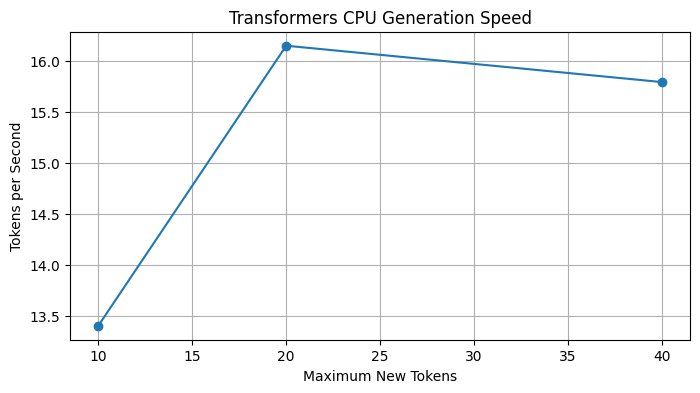

In [18]:
# 그래프 라이브러리 불러오기
import matplotlib.pyplot as plt

# 그래프 크기 설정
plt.figure(figsize=(8, 4))

# 최대 생성 토큰 수에 따른 속도 그래프
plt.plot(
    df["max_new_tokens"],
    df["tokens_per_second"],
    marker="o"
)

# 그래프 제목 설정
plt.title("Transformers CPU Generation Speed")

# 가로축 이름 설정
plt.xlabel("Maximum New Tokens")

# 세로축 이름 설정
plt.ylabel("Tokens per Second")

# 격자 표시
plt.grid(True)

# 그래프 출력
plt.show()

%pip install matplotlib pandas

실험 결과 CSV 저장

In [ ]:
# 실험 결과를 CSV 파일로 저장
df.to_csv(
    "02_Transformers_CPU_Results.csv",
    index=False,
    encoding="utf-8-sig"
)

# 저장 완료 메시지 출력
print("CSV 파일 저장 완료")

CSV 파일 저장 완료


: 

GitHub에 2회차 실습 업로드
Notebook을 Ctrl + S로 저장한 후 VS Code 터미널에서 실행한다.
# 2회차 Notebook과 CSV 파일 추가
git add 02_Transformers_CPU_Practice.ipynb 02_Transformers_CPU_Results.csv

# 2회차 실습 결과 기록
git commit -m "2회차 Transformers CPU 실습 완료"

# GitHub에 업로드
git push

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "Qwen/Qwen3-0.6B"

# 1. 토크나이저 불러오기
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 2. 언어 모델 불러오기
model = AutoModelForCausalLM.from_pretrained(model_name)
model = model.to("cpu")
model.eval()

# 3. 질문을 토큰 ID로 변환
text = "인공지능이란 무엇인가요?"

# tokenizer()는 입력 문장을 모델이 처리할 수 있는 숫자 데이터로 변환한다.
# return_tensors="pt"는 PyTorch 텐서(Tensor) 형식으로 반환하라는 의미
inputs = tokenizer(text, return_tensors="pt")

# 4. AI가 답변 생성
with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=False
    )

# 5. 새로 생성된 토큰만 문장으로 복원
new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
answer = tokenizer.decode(new_tokens, skip_special_tokens=True)

print("AI 답변:", answer)

tokenizer_config.json: 0.00B [00:00, ?B/s]

c:\python-llm-advanced\.venv\lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\seung\.cache\huggingface\hub\models--Qwen--Qwen3-0.6B. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors:   0%|          | 0.00/1.50G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


AI 답변:  그리고 AI의 기능은 무엇인가요?

AI는 인간의 감각, 기억, 판단, 그리고 사고를 기반으로 하는 인간의 본능을 기반으로 하는 기술입니다. AI는 인간의 감각, 기억, 판단, 그리고 사고를 기반으로 하는 인간의 본능을 기반으로 하는 기술입니다. AI는 인간의 감각, 기억, 판단, 그리고 사고를 기반으로 하는 인간의 본능을 기
